# TA05 - Experimentos com o MLP from scratch

CI1026 - Visão Computacional e Percepção (UFPR, Prof. Eduardo Todt)

Estudo e depuração do notebook de referência "Multi-Layer Perceptron from
scratch" (Iris, 3 classes), com análise de convergência, erros e
overfitting. Implementação 100% numpy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X, y = iris.data, iris.target
print(iris.DESCR.split('\n')[0], '| amostras:', X.shape[0], '| features:', X.shape[1])

.. _iris_dataset: | amostras: 150 | features: 4


## 1. Os dados

Setosa é trivialmente separável; a briga é versicolor x virginica, e as
features de pétala separam muito melhor que as de sépala.

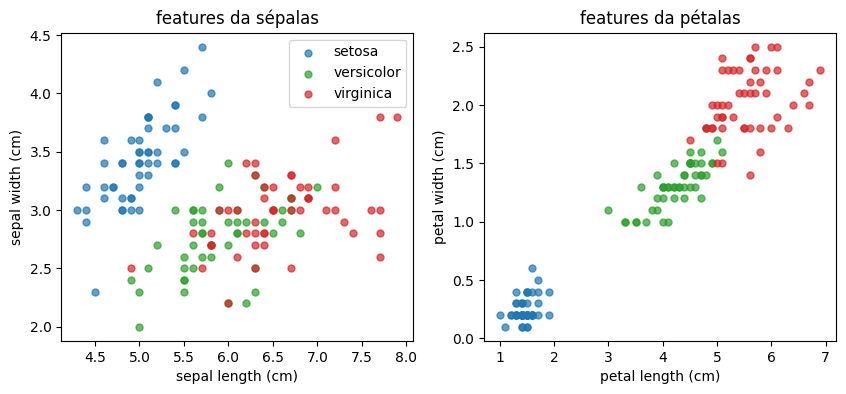

In [2]:
names = ['setosa', 'versicolor', 'virginica']
colors = ['#1f77b4', '#2ca02c', '#d62728']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, (feats, t) in enumerate([((0, 1), 'sépalas'), ((2, 3), 'pétalas')]):
    for c in range(3):
        m = y == c
        ax[k].scatter(X[m, feats[0]], X[m, feats[1]], s=25, alpha=.7,
                      c=colors[c], label=names[c])
    ax[k].set_xlabel(iris.feature_names[feats[0]])
    ax[k].set_ylabel(iris.feature_names[feats[1]])
    ax[k].set_title(f'features da {t}')
ax[0].legend(); plt.show()

## 2. Split e normalização

Mesmo split estratificado 80/20 do notebook de referência. O z-score é
ajustado só no treino, e ele importa: sem normalizar, as features ~1-7
saturam a sigmoid e a convergência arrasta (ver seção 4).

In [3]:
train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.2, random_state=11, stratify=y)

scaler = StandardScaler().fit(train_X)
train_Xn, test_Xn = scaler.transform(train_X), scaler.transform(test_X)
print('treino:', train_X.shape, '| teste:', test_X.shape)

treino: (120, 4) | teste: (30, 4)


## 3. O MLP, versão corrigida

O código de referência tem a mecânica do backprop certa, mas cinco bugs em
volta dela. O que esta versão corrige:

1. `predict` não aplicava a ativação (forward linear). Só esse fix já leva
   a mesma rede treinada de 33% pra 100% de acc.
2. `BIAS_output` era atualizado dentro do loop dos neurônios escondidos,
   andava `hiddenLayer`x por amostra com o update repetido.
3. `BIAS_*` era array de int (`np.array([-1,-1,-1])`); o `b[j] -= 0.4`
   truncava e o bias nunca aprendia.
4. `total_error` era acumulado dentro do loop das saídas com fator 0.05:
   o erro impresso saía ~4x menor que o MSE real.
5. Typo `iasHiddenValue`: `params=None` estoura `AttributeError`.

De quebra: seed reproduzível, histórico de loss/acurácia por época (treino
e validação) e `predict` coerente com o forward de treino.

In [4]:
class MultiLayerPerceptron:
    '''MLP 1 camada escondida, SGD por amostra, MSE + one-hot (como o original).'''

    ativacao = {
        'sigmoid': lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30))),
        'tanh':    lambda x: np.tanh(x),
        'relu':    lambda x: np.maximum(x, 0.0),
    }
    derivada = {  # derivadas em função da SAÍDA da ativação, como no original
        'sigmoid': lambda y: y * (1.0 - y),
        'tanh':    lambda y: 1.0 - y ** 2,
        'relu':    lambda y: 1.0 * (y > 0),
    }

    def __init__(self, input_dim=4, hidden=5, output_dim=3, lr=0.005,
                 epochs=600, activation='sigmoid', bias=-1.0, seed=None):
        self.hidden, self.output_dim = hidden, output_dim
        self.lr, self.epochs = lr, epochs
        self.activation = self.ativacao[activation]
        self.deriv = self.derivada[activation]
        rng = np.random.default_rng(seed)
        self.W1 = rng.uniform(-1, 1, (input_dim, hidden))
        self.W2 = rng.uniform(-1, 1, (hidden, output_dim))
        self.b1 = np.full(hidden, bias, dtype=float)      # bug 3: dtype=float!
        self.b2 = np.full(output_dim, bias, dtype=float)

    def _forward(self, x):
        h = self.activation(x @ self.W1 + self.b1)
        return h, self.activation(h @ self.W2 + self.b2)  # bug 1: ativação no predict

    def predict(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        return np.argmax([self._forward(x)[1] for x in X], axis=1)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y, dtype=int)))

    def mse(self, X, y):
        Y = np.eye(self.output_dim)[np.asarray(y, dtype=int)]
        P = np.array([self._forward(x)[1] for x in np.asarray(X, dtype=float)])
        return float(np.mean((Y - P) ** 2))                # bug 4: MSE de verdade

    def _backprop(self, x, target):
        h, o = self._forward(x)
        d_o = (o - target) * self.deriv(o)
        d_h = (self.W2 @ d_o) * self.deriv(h)   # gradiente exato: pesos ainda antigos
        self.W2 -= self.lr * np.outer(h, d_o)
        self.b2 -= self.lr * d_o                # bug 2: fora do loop dos escondidos
        self.W1 -= self.lr * np.outer(x, d_h)
        self.b1 -= self.lr * d_h

    def fit(self, X, y, X_val=None, y_val=None, log_every=25):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        hist = {'epoch': [], 'train_loss': [], 'train_acc': [],
                'val_loss': [], 'val_acc': []}
        for ep in range(1, self.epochs + 1):
            for xi, yi in zip(X, y):
                self._backprop(xi, np.eye(self.output_dim)[yi])
            if ep == 1 or ep % log_every == 0:
                hist['epoch'].append(ep)
                hist['train_loss'].append(self.mse(X, y))
                hist['train_acc'].append(self.score(X, y))
                if X_val is not None:
                    hist['val_loss'].append(self.mse(X_val, y_val))
                    hist['val_acc'].append(self.score(X_val, y_val))
        return hist

## 4. Convergência: dados crus vs. normalizados

Mesma arquitetura do notebook (4-5-3, sigmoid, lr=0.005) e mesmo seed. Com
features crus a sigmoid passa ~1500 épocas saturada antes de destravar;
normalizado, cai para MSE ~0.01 em poucas centenas de épocas.

features crus: acc teste = 1.000


normalizados (z-score): acc teste = 1.000


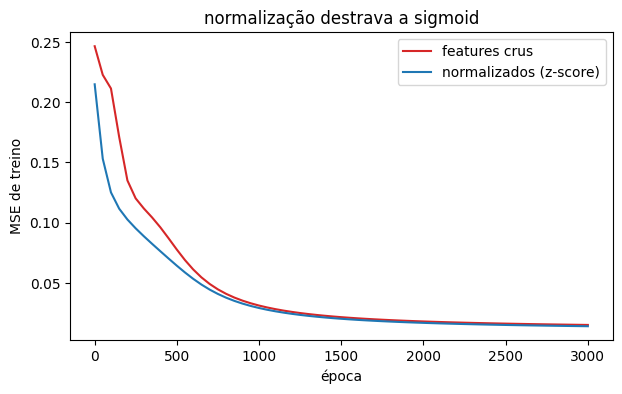

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for Xtr, Xte, lbl, c in [(train_X, test_X, 'features crus', '#d62728'),
                         (train_Xn, test_Xn, 'normalizados (z-score)', '#1f77b4')]:
    m = MultiLayerPerceptron(lr=0.005, epochs=3000, seed=0)
    h = m.fit(Xtr, train_y, log_every=50)
    print(f'{lbl}: acc teste = {m.score(Xte, test_y):.3f}')
    ax.plot(h['epoch'], h['train_loss'], c=c, label=lbl)
ax.set_xlabel('época'); ax.set_ylabel('MSE de treino')
ax.set_title('normalização destrava a sigmoid'); ax.legend(); plt.show()

## 5. Learning rate

A janela útil é bem larga (dados normalizados, H=5, sigmoid): o lr=0.005 do
notebook funciona, só é conservador. Abaixo de ~0.005 a rede não chega lá
nas épocas dadas; até lr=2.0 o MSE+sigmoid segue estável.

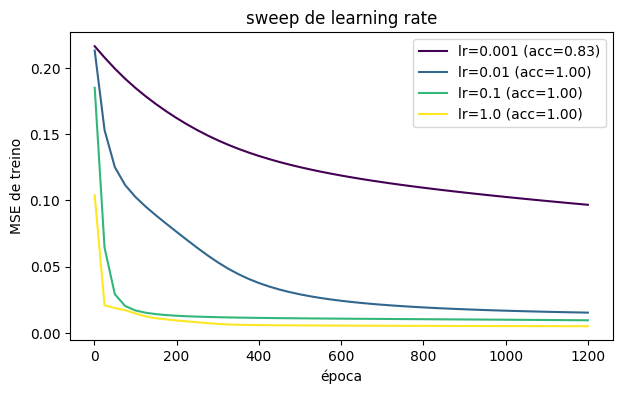

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr, c in zip([0.001, 0.01, 0.1, 1.0], plt.cm.viridis([0, .33, .66, 1])):
    m = MultiLayerPerceptron(lr=lr, epochs=1200, seed=0)
    h = m.fit(train_Xn, train_y, log_every=25)
    ax.plot(h['epoch'], h['train_loss'], c=c,
            label=f'lr={lr} (acc={m.score(test_Xn, test_y):.2f})')
ax.set_xlabel('época'); ax.set_ylabel('MSE de treino')
ax.set_title('sweep de learning rate'); ax.legend(); plt.show()

## 6. Função de ativação: a ReLU morta

Com bias inicial -1 (o default do notebook), a ReLU vira **rede morta**:
pré-ativações negativos -> saída 0 -> gradiente 0 -> nada aprende, e a rede
prevê uma classe só (~33%). Bias 0 reanima parcialmente, mas segue
instável. Sigmoid e tanh fecham 100%, e é por isso que o original usa sigmoid.

sigmoid (bias=-1): acc = 1.000 ± 0.000


tanh (bias=-1): acc = 1.000 ± 0.000


relu (bias=-1): acc = 0.322 ± 0.016


relu (bias=+0): acc = 0.889 ± 0.157


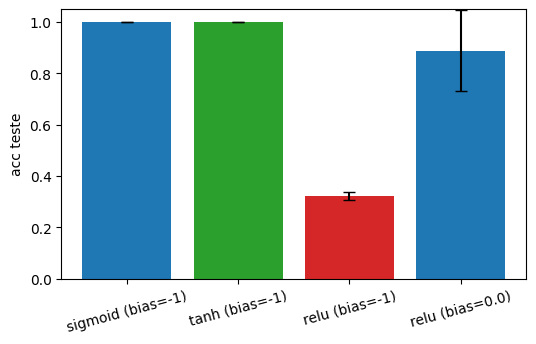

In [7]:
rows = []
for act, bias in [('sigmoid', -1), ('tanh', -1), ('relu', -1), ('relu', 0.0)]:
    accs = []
    for s in range(3):
        m = MultiLayerPerceptron(lr=0.05, epochs=800, activation=act,
                                 bias=bias, seed=s)
        m.fit(train_Xn, train_y, log_every=999)
        accs.append(m.score(test_Xn, test_y))
    rows.append((f'{act} (bias={bias})', np.mean(accs), np.std(accs)))
    print(f'{act} (bias={bias:+.0f}): acc = {np.mean(accs):.3f} ± {np.std(accs):.3f}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([r[0] for r in rows], [r[1] for r in rows],
       yerr=[r[2] for r in rows], capsize=4, color=colors[:4])
ax.set_ylim(0, 1.05); ax.set_ylabel('acc teste'); plt.xticks(rotation=15)
plt.show()

## 7. Overfitting

Com os dados limpos, nem uma rede 4-64-3 overfitta, o Iris é separável
demais. Para enxergar o fenômeno, injetei 20% de rótulos embaralhados no
treino: o modelo grande memoriza o ruído (acurácia de treino, medida
contra os rótulos ruidosos, sobe) enquanto a validação limpa cai e o
`val_loss` diverge. O remédio: early stopping na melhor época de validação,
ou menos capacidade.

H=64: melhor val na época 50 (acc=1.00); final: val=0.97, treino*=0.92


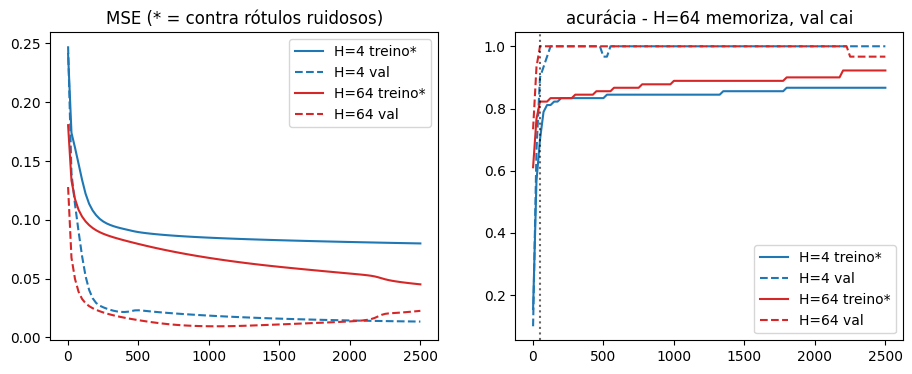

In [8]:
tr_X, val_X, tr_y, val_y = train_test_split(
    train_Xn, train_y, test_size=0.25, random_state=7, stratify=train_y)

rng = np.random.default_rng(3)
tr_y_noise = tr_y.copy()
idx = rng.choice(len(tr_y), size=int(0.2 * len(tr_y)), replace=False)
tr_y_noise[idx] = rng.integers(0, 3, size=len(idx))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for H, c in [(4, '#1f77b4'), (64, '#d62728')]:
    m = MultiLayerPerceptron(hidden=H, lr=0.05, epochs=2500, seed=0)
    h = m.fit(tr_X, tr_y_noise, X_val=val_X, y_val=val_y)
    axes[0].plot(h['epoch'], h['train_loss'], c=c, label=f'H={H} treino*')
    axes[0].plot(h['epoch'], h['val_loss'], c=c, ls='--', label=f'H={H} val')
    axes[1].plot(h['epoch'], h['train_acc'], c=c, label=f'H={H} treino*')
    axes[1].plot(h['epoch'], h['val_acc'], c=c, ls='--', label=f'H={H} val')
    if H == 64:
        best_ep = h['epoch'][int(np.argmax(h['val_acc']))]
        axes[1].axvline(best_ep, c='k', ls=':', alpha=.6)
        print(f'H=64: melhor val na época {best_ep} (acc={max(h["val_acc"]):.2f}); '
              f'final: val={h["val_acc"][-1]:.2f}, treino*={h["train_acc"][-1]:.2f}')
axes[0].set_title('MSE (* = contra rótulos ruidosos)'); axes[0].legend()
axes[1].set_title('acurácia - H=64 memoriza, val cai'); axes[1].legend()
plt.show()

## 8. Modelo final

Receita (o que os experimentos mostraram): **predict com ativação + features
normalizados + sigmoid + lr 0.05 + H=8 + ~800 épocas** -> 100% no teste.

acc de teste: 1.000


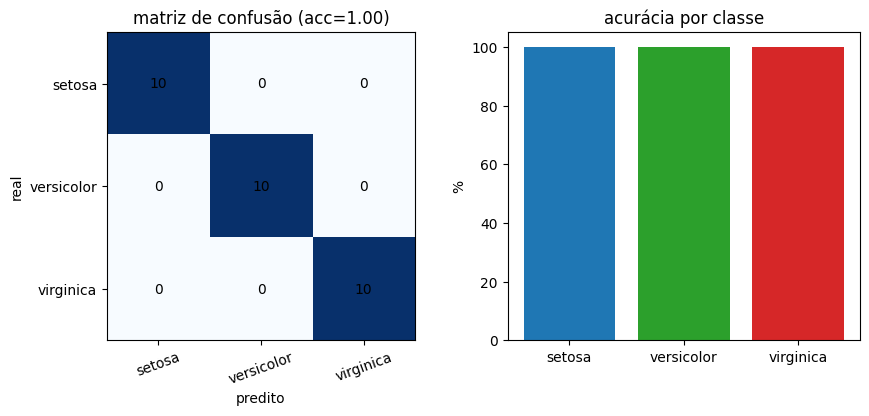

In [9]:
best = MultiLayerPerceptron(hidden=8, lr=0.05, epochs=800, seed=0)
best.fit(train_Xn, train_y, log_every=999)
pred = best.predict(test_Xn)
acc = best.score(test_Xn, test_y)
print(f'acc de teste: {acc:.3f}')

cm = np.zeros((3, 3), dtype=int)
for t, p in zip(test_y, pred):
    cm[t, p] += 1
per_class = cm.diagonal() / cm.sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, cm[i, j], ha='center', va='center')
ax[0].set_xticks(range(3), names, rotation=20); ax[0].set_yticks(range(3), names)
ax[0].set_xlabel('predito'); ax[0].set_ylabel('real')
ax[0].set_title(f'matriz de confusão (acc={acc:.2f})')
ax[1].bar(names, per_class * 100, color=colors)
ax[1].set_ylim(0, 105); ax[1].set_ylabel('%'); ax[1].set_title('acurácia por classe')
plt.show()

E como as pétalas carregam quase tudo, uma rede 2-8-3 treinada só em
`petal length/width` também fecha 100%. As regiões de decisão:

acc teste (só pétalas): 1.0


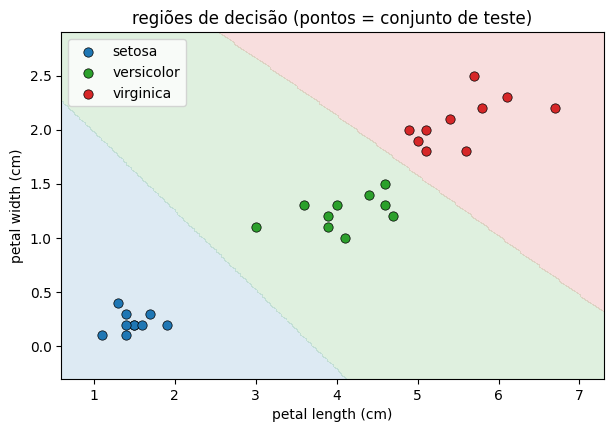

In [10]:
sc2 = StandardScaler().fit(train_X[:, 2:4])
m2 = MultiLayerPerceptron(input_dim=2, hidden=8, lr=0.05, epochs=800, seed=0)
m2.fit(sc2.transform(train_X[:, 2:4]), train_y, log_every=999)
print('acc teste (só pétalas):', m2.score(sc2.transform(test_X[:, 2:4]), test_y))

xx, yy = np.meshgrid(np.linspace(X[:, 2].min() - .4, X[:, 2].max() + .4, 200),
                     np.linspace(X[:, 3].min() - .4, X[:, 3].max() + .4, 200))
Z = m2.predict(sc2.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
plt.figure(figsize=(7, 4.5))
plt.contourf(xx, yy, Z, levels=2, colors=colors, alpha=.15)
for c in range(3):
    plt.scatter(test_X[test_y == c, 2], test_X[test_y == c, 3], s=45,
                c=colors[c], edgecolors='k', linewidths=.5, label=names[c])
plt.xlabel(iris.feature_names[2]); plt.ylabel(iris.feature_names[3])
plt.title('regiões de decisão (pontos = conjunto de teste)'); plt.legend()
plt.show()

## 9. Conclusões

- O backprop da referência estava certo; os bugs em volta é que derrubavam
  o resultado, principalmente o `predict` sem ativação (33% -> 100%).
- Para classificar bem as 3 classes: normalizar, sigmoid/tanh, lr ~0.05,
  H pequeno e early stopping -> 100% no teste, sem mistério.
- Overfitting no Iris limpo não aparece nem com H=64; com rótulos
  ruidosos, o modelo grande memoriza e a validação denuncia.